# Possession typologies

The eight typologies summarize different hazard-band trajectories and terminal outcomes. Each category has the same structure in the report: definition, league-level share, and an example case. Criteria are project-defined; names draw on SkillCorner Game Intelligence vocabulary. **design choice**

## Model and inputs

Bands rank None < Low < Medium < High. “Attracted risk” means the sequence starts in None/Low, ends High, and retains possession; it is evaluated before “Retained Under Intense Risk” to make the classes disjoint. A loss after any elevated risk is separated by whether the sequence de-escalated. Low-band losses form “Unexpected Loss”; the real `on_ball_engagement` flag is retained as case context, not a ninth category. **design choice**.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

Names inspired by SkillCorner terminology [@skillcorner-pressure]; thresholds and criteria are **design choice**.

These categories are rule-based summaries of the hazard-band sequence and possession outcome. They are not model outputs or causal explanations. Real on-ball engagement is preserved as case context; it does not create an extra category. **design choice**


                      category  ...                      toy_case_study
0       Instant High-Risk Loss  ...           ['High', 'High'] · loss=1
1             Pressing to Loss  ...  ['Low', 'Medium', 'High'] · loss=1
2        De-escalated but Lost  ...  ['Low', 'High', 'Medium'] · loss=1
3                 Escaped Risk  ...     ['Low', 'High', 'Low'] · loss=0
4  Retained Under Intense Risk  ...         ['Medium', 'High'] · loss=0
5               Attracted risk  ...            ['Low', 'High'] · loss=0
6              Unexpected Loss  ...             ['Low', 'Low'] · loss=1
7            Ordinary/Low-Risk  ...            ['None', 'Low'] · loss=0

[8 rows x 4 columns]


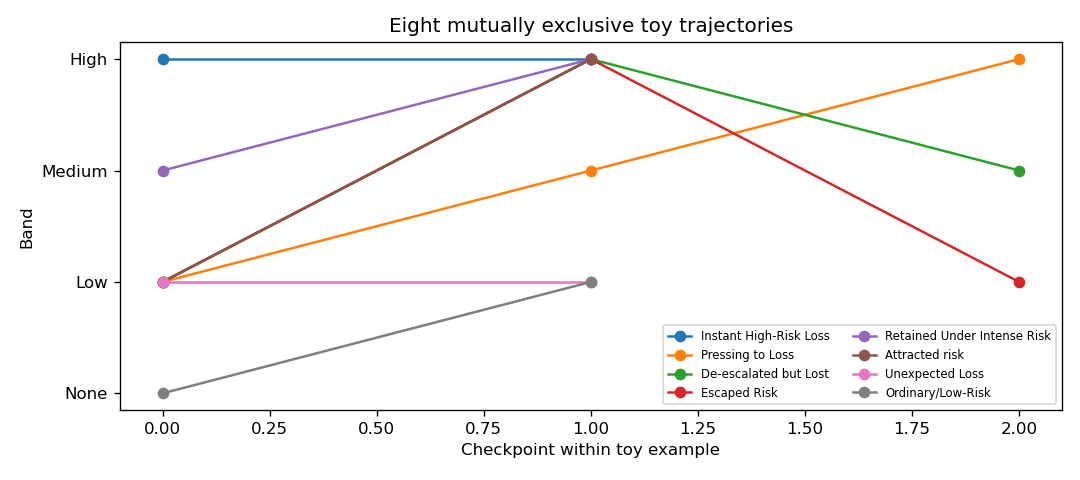

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
rank={"None":0,"Low":1,"Medium":2,"High":3}
def classify(bands,lost,engagement=False):
 r=[rank[x] for x in bands]; elevated=max(r)>=2; deescalated=any(r[i] < max(r[:i]) for i in range(1,len(r)))
 if bands[0]=="High" and lost: return "Instant High-Risk Loss"
 if bands[0] in ("None","Low") and bands[-1]=="High" and not lost: return "Attracted risk"
 if elevated and lost and not deescalated: return "Pressing to Loss"
 if elevated and lost: return "De-escalated but Lost"
 if elevated and not lost and deescalated: return "Escaped Risk"
 if elevated and not lost: return "Retained Under Intense Risk"
 if lost: return "Unexpected Loss"
 return "Ordinary/Low-Risk"
examples=[["High","High"],["Low","Medium","High"],["Low","High","Medium"],["Low","High","Low"],["Medium","High"],["Low","High"],["Low","Low"],["None","Low"]]; lost=[1,1,1,0,0,0,1,0]; labels=[classify(b,l) for b,l in zip(examples,lost)]
fig,ax=plt.subplots(figsize=(9,4));
for i,(b,lbl) in enumerate(zip(examples,labels)): ax.plot(range(len(b)),[rank[x] for x in b],marker="o",label=lbl)
ax.set(yticks=[0,1,2,3],yticklabels=list(rank),xlabel="Checkpoint within toy example",ylabel="Band",title="Eight mutually exclusive toy trajectories"); ax.legend(fontsize=7,ncol=2); fig.tight_layout()
out=Path("figures/vignette_08_typologies.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))
definitions={"Instant High-Risk Loss":"Starts High and ends in loss.","Pressing to Loss":"Reaches Medium/High, loses possession, and has no drop after an earlier peak.","De-escalated but Lost":"Reaches Medium/High, drops below an earlier peak, then ends in loss.","Escaped Risk":"Reaches Medium/High, drops below an earlier peak, and retains possession.","Retained Under Intense Risk":"Reaches Medium/High without a later drop and retains possession.","Attracted risk":"Starts None/Low, ends High, and retains possession.","Unexpected Loss":"Never reaches Medium/High and ends in loss; engagement is retained as case context.","Ordinary/Low-Risk":"Never reaches Medium/High and retains possession."}
import pandas as pd
counts=pd.Series(labels).value_counts()
rows=[]
for name,definition in definitions.items():
 i=labels.index(name); rows.append({"category":name,"definition":definition,"toy_share":float(counts.get(name,0)/len(labels)),"toy_case_study":f"{examples[i]} · loss={lost[i]}"})
from IPython.display import display
display(pd.DataFrame(rows))